# 🧬 Breast Cancer Prediction Engine
### Machine Learning-Powered Diagnostic Classification System

This notebook implements a complete ML pipeline for classifying breast tumors as **benign** or **malignant** using the Wisconsin Diagnostic Dataset.

**Pipeline Overview:**
1. Data Loading & Exploration
2. Data Preprocessing & Feature Engineering
3. Model Training (Logistic Regression + 4 additional models)
4. Comprehensive Evaluation (Confusion Matrix, ROC-AUC, Classification Report)
5. Cross-Validation
6. Model Comparison

## 1. 📦 Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.datasets
import warnings

# Sklearn - Preprocessing & Splitting
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# Sklearn - Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Sklearn - Metrics
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score
)

# Sklearn - Preprocessing
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Plot styling
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

COLORS = {
    'benign': '#2ecc71',
    'malignant': '#e74c3c',
    'primary': '#3498db',
    'secondary': '#9b59b6',
    'accent': '#f39c12'
}

print("✅ All libraries imported successfully!")

/home/gemechu/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


✅ All libraries imported successfully!


## 2. 📊 Data Collection & Exploration

In [2]:
# Load the Breast Cancer Wisconsin dataset
breast_cancer_dataset = sklearn.datasets.load_breast_cancer()

# Create DataFrame
data_frame = pd.DataFrame(breast_cancer_dataset.data, columns=breast_cancer_dataset.feature_names)
data_frame['label'] = breast_cancer_dataset.target

print(f"📋 Dataset Shape: {data_frame.shape[0]} samples × {data_frame.shape[1]} columns")
print(f"🔢 Features: {len(breast_cancer_dataset.feature_names)}")
print(f"🏷️  Classes: {list(breast_cancer_dataset.target_names)}")
print(f"❌ Missing Values: {data_frame.isnull().sum().sum()}")
print()
data_frame.head()

📋 Dataset Shape: 569 samples × 31 columns
🔢 Features: 30
🏷️  Classes: [np.str_('malignant'), np.str_('benign')]
❌ Missing Values: 0



,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Detailed dataset info
data_frame.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [4]:
# Statistical summary
data_frame.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


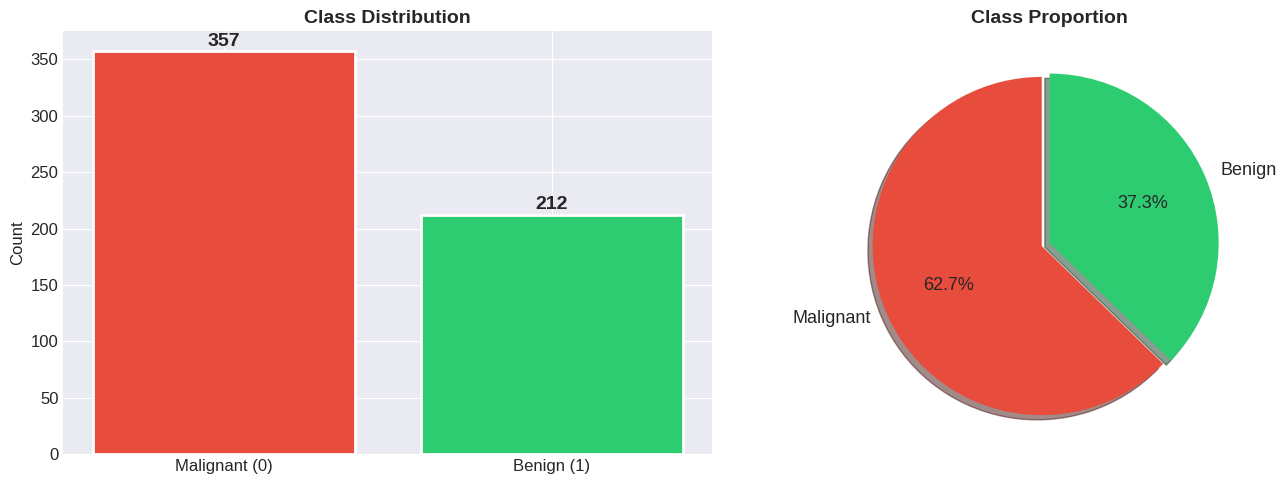


1 → Benign (non-cancerous)
0 → Malignant (cancerous)


In [5]:
# Class distribution
class_counts = data_frame['label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
bars = axes[0].bar(['Malignant (0)', 'Benign (1)'], class_counts.values,
                    color=[COLORS['malignant'], COLORS['benign']], edgecolor='white', linewidth=2)
axes[0].set_title('Class Distribution', fontweight='bold')
axes[0].set_ylabel('Count')
for bar, count in zip(bars, class_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 5,
                 f'{count}', ha='center', fontweight='bold', fontsize=14)

# Pie chart
axes[1].pie(class_counts.values, labels=['Malignant', 'Benign'],
            colors=[COLORS['malignant'], COLORS['benign']],
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 13},
            explode=(0.05, 0), shadow=True)
axes[1].set_title('Class Proportion', fontweight='bold')

plt.tight_layout()
plt.savefig('../images/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n1 → Benign (non-cancerous)")
print("0 → Malignant (cancerous)")

In [6]:
# Mean feature values by class
data_frame.groupby('label').mean().T.head(10)

label,0,1
mean radius,17.462830,12.146524
mean texture,21.604906,17.914762
mean perimeter,115.365377,78.075406
mean area,978.376415,462.790196
mean smoothness,0.102898,0.092478
mean compactness,0.145188,0.080085
mean concavity,0.160775,0.046058
mean concave points,0.087990,0.025717
mean symmetry,0.192909,0.174186
mean fractal dimension,0.062680,0.062867


## 3. 📈 Data Visualization

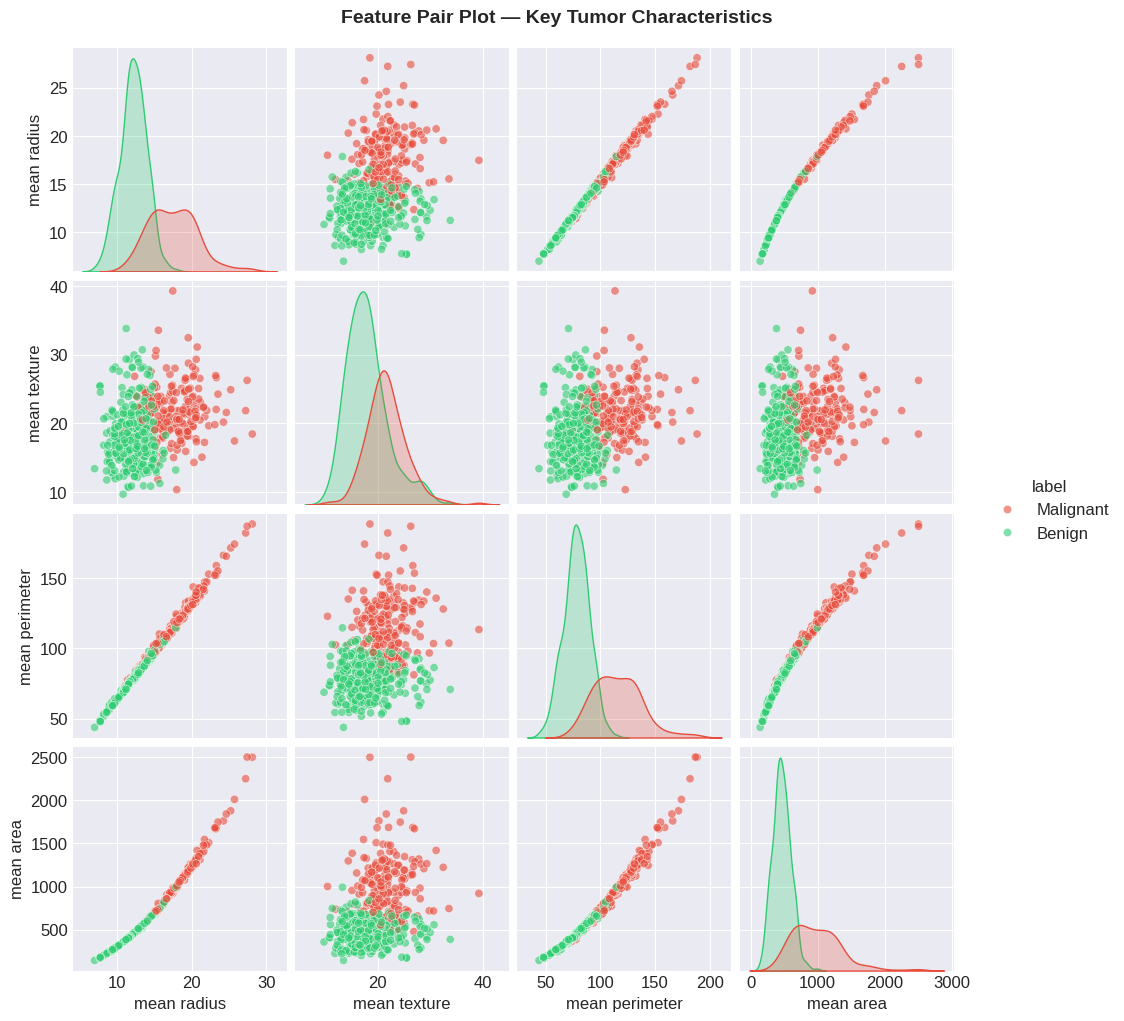

In [7]:
# Pair plot of key features
key_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']
plot_df = data_frame[key_features + ['label']].copy()
plot_df['label'] = plot_df['label'].map({0: 'Malignant', 1: 'Benign'})

g = sns.pairplot(plot_df, hue='label', palette={'Malignant': COLORS['malignant'], 'Benign': COLORS['benign']},
                 diag_kind='kde', plot_kws={'alpha': 0.6, 'edgecolor': 'white', 'linewidth': 0.5})
g.figure.suptitle('Feature Pair Plot — Key Tumor Characteristics', y=1.02, fontweight='bold', fontsize=14)
plt.savefig('../images/pairplot.png', dpi=150, bbox_inches='tight')
plt.show()

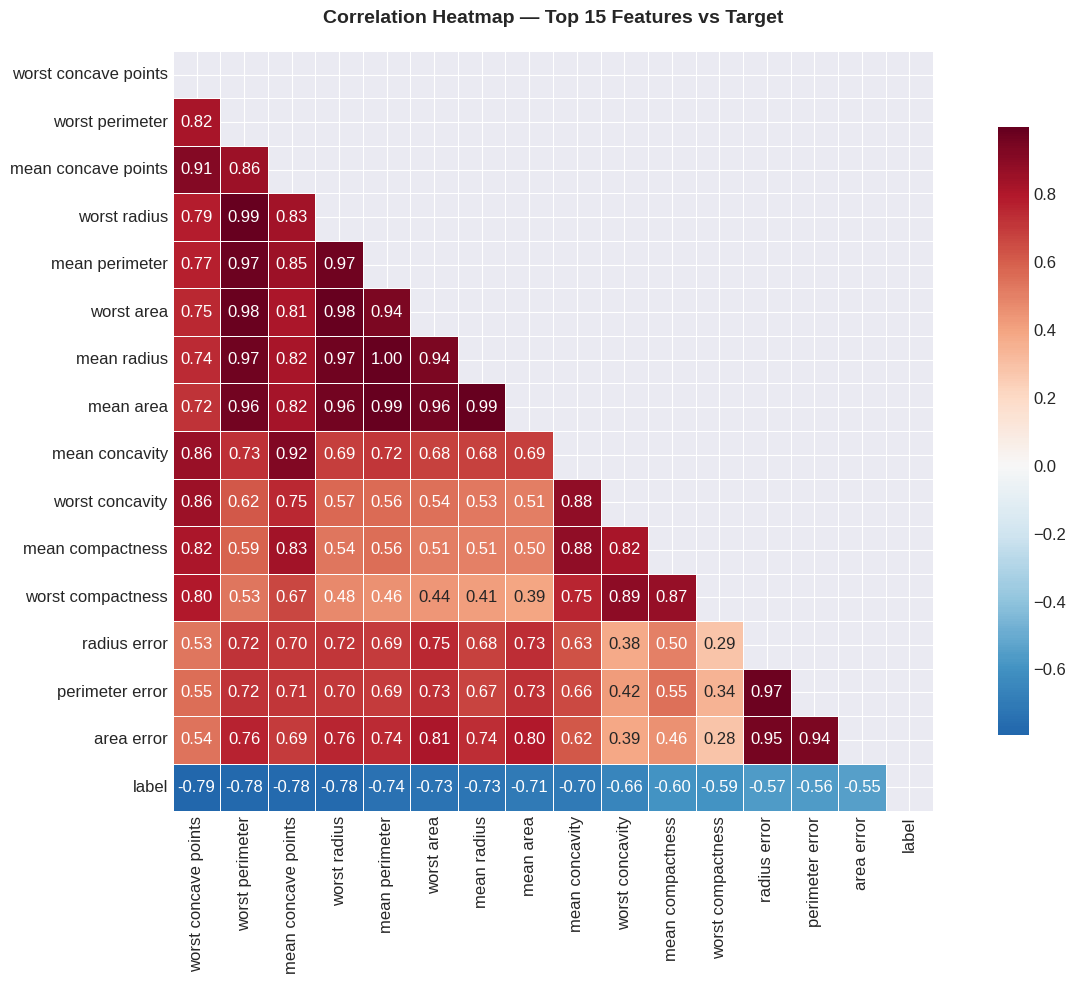

In [8]:
# Correlation heatmap of top features
fig, ax = plt.subplots(figsize=(14, 10))
top_features = data_frame.drop('label', axis=1).corrwith(data_frame['label']).abs().nlargest(15).index.tolist()
corr_matrix = data_frame[top_features + ['label']].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap — Top 15 Features vs Target', fontweight='bold', pad=20)
plt.savefig('../images/correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.tight_layout()
plt.show()

## 4. 🧹 Data Preprocessing

In [9]:
# Separate features and target
X = data_frame.drop(columns='label', axis=1)
y = data_frame['label']

print(f"Features shape: {X.shape}")
print(f"Target shape:   {y.shape}")

Features shape: (569, 30)
Target shape:   (569,)


In [10]:
# Train/Test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")
print(f"\nTraining class balance: {dict(y_train.value_counts())}")
print(f"Test class balance:     {dict(y_test.value_counts())}")

Training set: 455 samples
Test set:     114 samples

Training class balance: {1: np.int64(285), 0: np.int64(170)}
Test class balance:     {1: np.int64(72), 0: np.int64(42)}


In [11]:
# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Features scaled using StandardScaler")

✅ Features scaled using StandardScaler


## 4.5 🔬 Advanced Feature Engineering & Dimensionality Reduction

Before training our final models, let's analyze feature importance and apply Principal Component Analysis (PCA) to understand the underlying structure of our data.

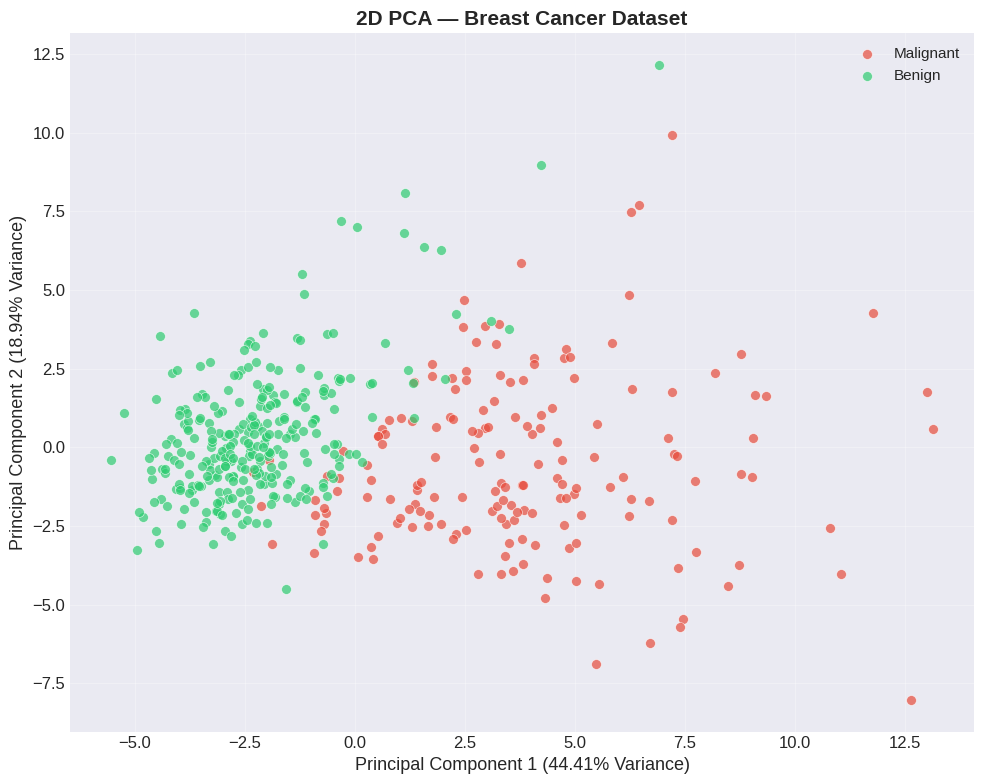

Total variance explained by 2 components: 63.36%


In [12]:
from sklearn.decomposition import PCA

# Apply PCA to reduce dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

# Create a DataFrame for visualization
pca_df = pd.DataFrame(data = X_pca, columns = ['Principal Component 1', 'Principal Component 2'])
pca_df['Target'] = y_train.values

fig, ax = plt.subplots(figsize=(10, 8))
targets = [0, 1]
colors = [COLORS['malignant'], COLORS['benign']]
labels = ['Malignant', 'Benign']

for target, color, label in zip(targets, colors, labels):
    indicesToKeep = pca_df['Target'] == target
    ax.scatter(pca_df.loc[indicesToKeep, 'Principal Component 1'],
               pca_df.loc[indicesToKeep, 'Principal Component 2'],
               c=color, s=50, alpha=0.7, label=label, edgecolor='white', linewidth=0.5)

ax.set_xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.2%} Variance)", fontsize=13)
ax.set_ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.2%} Variance)", fontsize=13)
ax.set_title('2D PCA — Breast Cancer Dataset', fontweight='bold', fontsize=15)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../images/pca_2d.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Total variance explained by 2 components: {sum(pca.explained_variance_ratio_):.2%}")

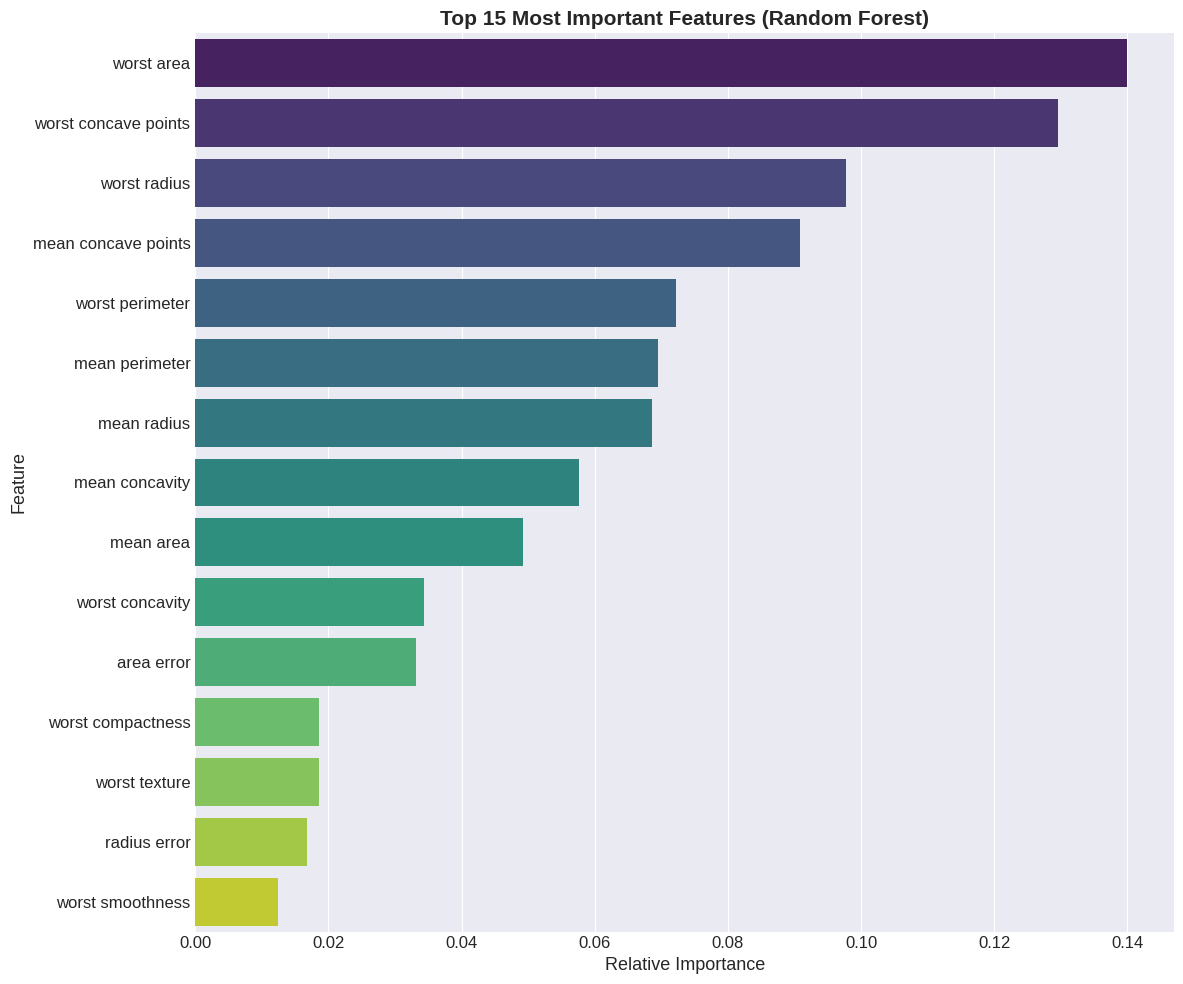

Top 5 most critical features for diagnosis:
['worst area', 'worst concave points', 'worst radius', 'mean concave points', 'worst perimeter']


In [13]:
# Train a quick Random Forest to extract Feature Importances
rf_importance = RandomForestClassifier(n_estimators=100, random_state=42)
rf_importance.fit(X_train_scaled, y_train)

# Create DataFrame of importances
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_importance.feature_importances_
}).sort_values(by='Importance', ascending=False)

fig, ax = plt.subplots(figsize=(12, 10))
sns.barplot(x='Importance', y='Feature', data=importances.head(15), 
            palette='viridis', ax=ax)

ax.set_title('Top 15 Most Important Features (Random Forest)', fontweight='bold', fontsize=15)
ax.set_xlabel('Relative Importance', fontsize=13)
ax.set_ylabel('Feature', fontsize=13)

plt.tight_layout()
plt.savefig('../images/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

top_5_features = importances['Feature'].head(5).tolist()
print(f"Top 5 most critical features for diagnosis:\n{top_5_features}")

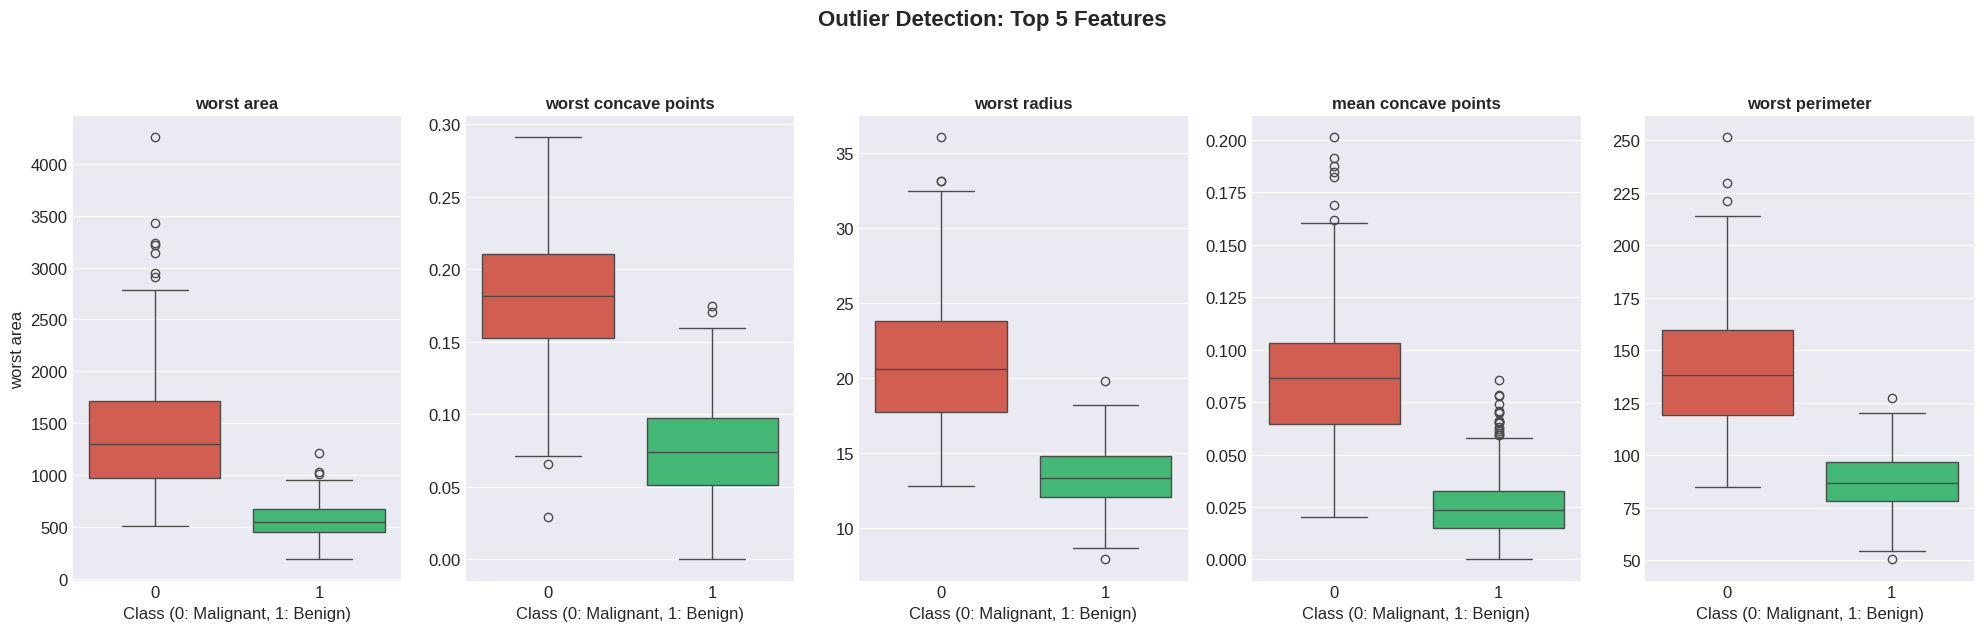

In [14]:
# Box plots for the top 5 most important features
fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for idx, feature in enumerate(top_5_features):
    sns.boxplot(x='label', y=feature, data=data_frame, ax=axes[idx],
                palette={0: COLORS['malignant'], 1: COLORS['benign'], '0': COLORS['malignant'], '1': COLORS['benign']})
    axes[idx].set_title(feature, fontweight='bold', fontsize=12)
    axes[idx].set_xlabel('Class (0: Malignant, 1: Benign)')
    if idx > 0:
        axes[idx].set_ylabel('')

plt.suptitle('Outlier Detection: Top 5 Features', fontweight='bold', fontsize=16, y=1.05)
plt.tight_layout()
plt.savefig('../images/boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. 🤖 Model Training

We train **5 different classifiers** and compare their performance:

| # | Model | Type |
|---|-------|------|
| 1 | Logistic Regression | Linear |
| 2 | Random Forest | Ensemble |
| 3 | Support Vector Machine | Kernel-based |
| 4 | K-Nearest Neighbors | Instance-based |
| 5 | Gradient Boosting | Boosted Ensemble |

In [15]:
# Define models
models = {
    'Logistic Regression': LogisticRegression(max_iter=10000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# Train all models and store results
results = {}

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)
    
    # Predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    
    # Probabilities (for ROC curve)
    if hasattr(model, 'predict_proba'):
        y_test_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_test_proba = model.decision_function(X_test_scaled)
    
    # Store results
    results[name] = {
        'model': model,
        'y_train_pred': y_train_pred,
        'y_test_pred': y_test_pred,
        'y_test_proba': y_test_proba,
        'train_acc': accuracy_score(y_train, y_train_pred),
        'test_acc': accuracy_score(y_test, y_test_pred),
        'f1': f1_score(y_test, y_test_pred),
        'precision': precision_score(y_test, y_test_pred),
        'recall': recall_score(y_test, y_test_pred),
    }
    
    print(f"✅ {name:25s} | Train: {results[name]['train_acc']:.4f} | Test: {results[name]['test_acc']:.4f} | F1: {results[name]['f1']:.4f}")

print("\n🎯 All models trained successfully!")

✅ Logistic Regression       | Train: 0.9890 | Test: 0.9825 | F1: 0.9861


✅ Random Forest             | Train: 1.0000 | Test: 0.9561 | F1: 0.9655
✅ SVM                       | Train: 0.9824 | Test: 0.9825 | F1: 0.9861
✅ KNN                       | Train: 0.9736 | Test: 0.9561 | F1: 0.9655


✅ Gradient Boosting         | Train: 1.0000 | Test: 0.9561 | F1: 0.9660

🎯 All models trained successfully!


## 6. 📊 Model Evaluation

### 6.1 Confusion Matrices

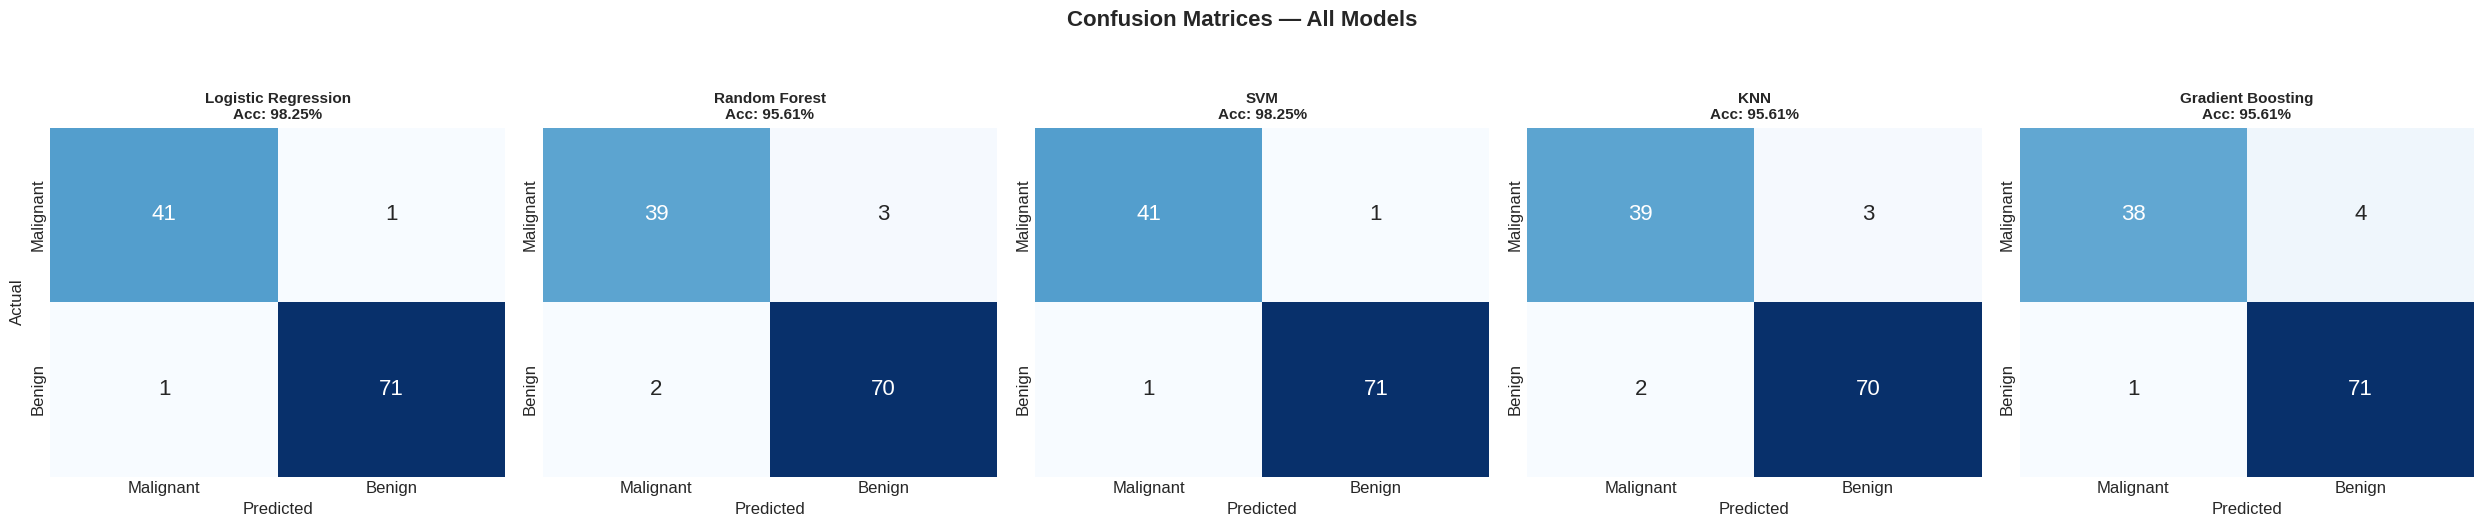

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for idx, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res['y_test_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Malignant', 'Benign'],
                yticklabels=['Malignant', 'Benign'],
                cbar=False, annot_kws={'size': 16})
    axes[idx].set_title(f'{name}\nAcc: {res["test_acc"]:.2%}', fontweight='bold', fontsize=11)
    axes[idx].set_ylabel('Actual' if idx == 0 else '')
    axes[idx].set_xlabel('Predicted')

plt.suptitle('Confusion Matrices — All Models', fontweight='bold', fontsize=16, y=1.05)
plt.tight_layout()
plt.savefig('../images/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.2 Classification Reports

In [17]:
for name, res in results.items():
    print(f"{'='*60}")
    print(f"  📋 {name}")
    print(f"{'='*60}")
    print(classification_report(y_test, res['y_test_pred'],
                                target_names=['Malignant', 'Benign']))

  📋 Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

  📋 Random Forest
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

  📋 SVM
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98 

### 6.3 ROC-AUC Curves

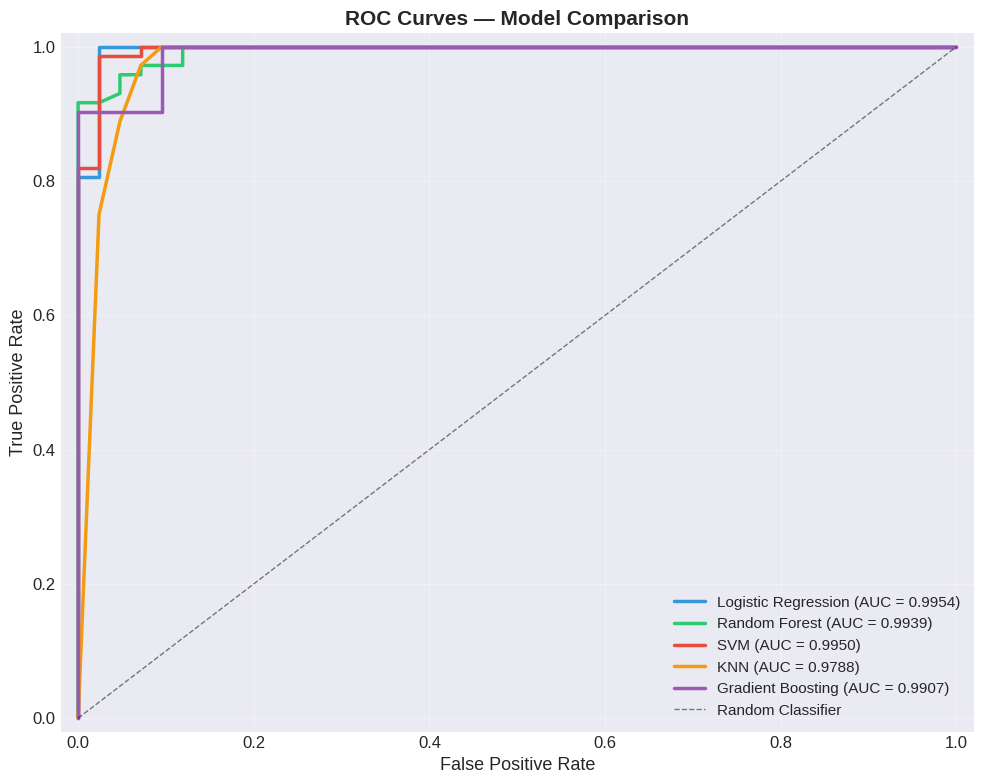

In [18]:
fig, ax = plt.subplots(figsize=(10, 8))

colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']

for (name, res), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, res['y_test_proba'])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2.5, label=f'{name} (AUC = {roc_auc:.4f})')

# Diagonal reference line
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, linewidth=1, label='Random Classifier')

ax.set_xlabel('False Positive Rate', fontsize=13)
ax.set_ylabel('True Positive Rate', fontsize=13)
ax.set_title('ROC Curves — Model Comparison', fontweight='bold', fontsize=15)
ax.legend(loc='lower right', fontsize=11, framealpha=0.9)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../images/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.4 Precision-Recall Curves

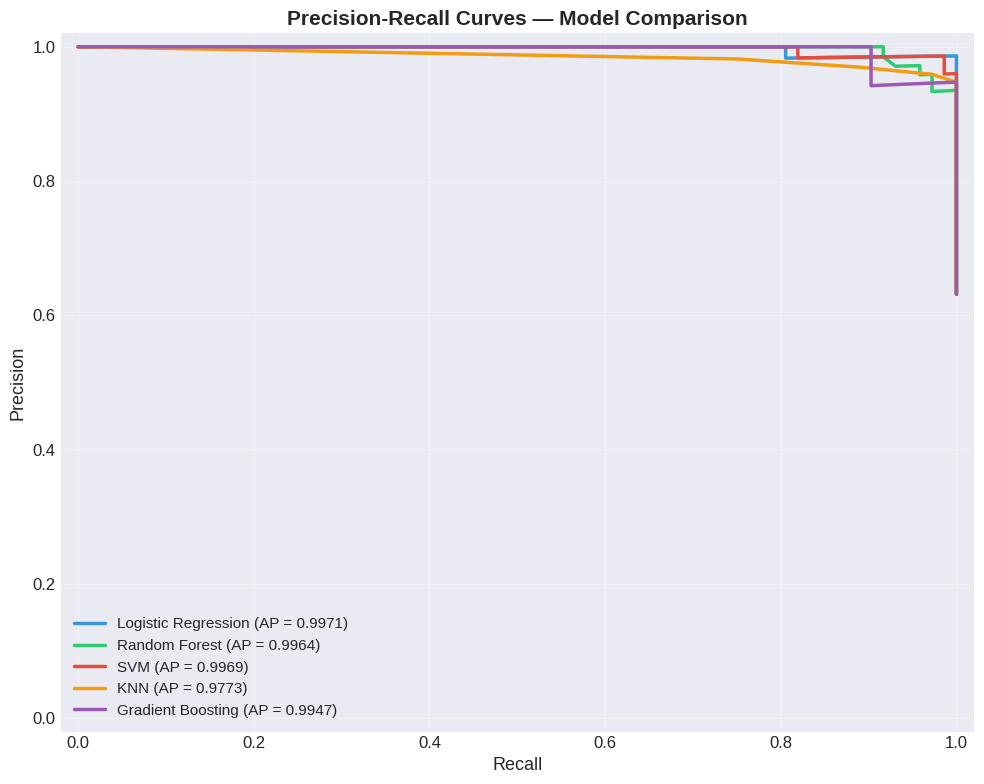

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))

for (name, res), color in zip(results.items(), colors):
    precision_vals, recall_vals, _ = precision_recall_curve(y_test, res['y_test_proba'])
    ap = average_precision_score(y_test, res['y_test_proba'])
    ax.plot(recall_vals, precision_vals, color=color, linewidth=2.5,
            label=f'{name} (AP = {ap:.4f})')

ax.set_xlabel('Recall', fontsize=13)
ax.set_ylabel('Precision', fontsize=13)
ax.set_title('Precision-Recall Curves — Model Comparison', fontweight='bold', fontsize=15)
ax.legend(loc='lower left', fontsize=11, framealpha=0.9)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../images/precision_recall_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. 🔄 Cross-Validation (5-Fold Stratified)

A single train/test split can be misleading. Cross-validation gives a more robust estimate of model performance.

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}

print(f"{'Model':<25} {'Mean Acc':>10} {'Std':>8} {'Min':>8} {'Max':>8}")
print("─" * 62)

for name, model_cfg in models.items():
    # Create a fresh model instance
    scores = cross_val_score(model_cfg, scaler.fit_transform(X), y, cv=cv, scoring='accuracy')
    cv_results[name] = scores
    print(f"{name:<25} {scores.mean():>10.4f} {scores.std():>8.4f} {scores.min():>8.4f} {scores.max():>8.4f}")

Model                       Mean Acc      Std      Min      Max
──────────────────────────────────────────────────────────────
Logistic Regression           0.9737   0.0166   0.9474   0.9912


Random Forest                 0.9561   0.0123   0.9386   0.9735
SVM                           0.9754   0.0195   0.9386   0.9912
KNN                           0.9666   0.0140   0.9474   0.9825


Gradient Boosting             0.9491   0.0237   0.9035   0.9735


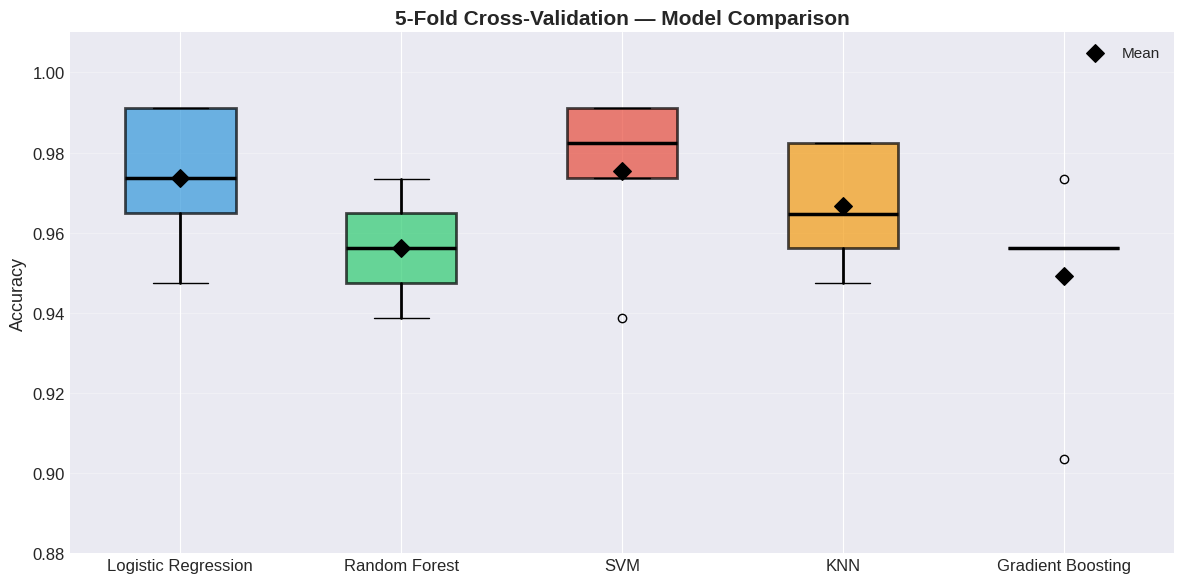

In [21]:
# Cross-validation box plot
fig, ax = plt.subplots(figsize=(12, 6))

cv_data = pd.DataFrame(cv_results)
bp = ax.boxplot(cv_data.values, labels=cv_data.columns, patch_artist=True,
                boxprops=dict(linewidth=2),
                whiskerprops=dict(linewidth=2),
                medianprops=dict(linewidth=2.5, color='black'))

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_ylabel('Accuracy', fontsize=13)
ax.set_title('5-Fold Cross-Validation — Model Comparison', fontweight='bold', fontsize=15)
ax.set_ylim([0.88, 1.01])
ax.grid(True, alpha=0.3, axis='y')

# Add mean markers
means = cv_data.mean()
ax.scatter(range(1, len(means)+1), means, color='black', zorder=5, s=80, marker='D', label='Mean')
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('../images/cross_validation.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. 🏆 Final Model Comparison

In [22]:
# Build comparison DataFrame
comparison = pd.DataFrame({
    'Model': list(results.keys()),
    'Train Accuracy': [r['train_acc'] for r in results.values()],
    'Test Accuracy': [r['test_acc'] for r in results.values()],
    'Precision': [r['precision'] for r in results.values()],
    'Recall': [r['recall'] for r in results.values()],
    'F1-Score': [r['f1'] for r in results.values()],
    'CV Mean Acc': [cv_results[name].mean() for name in results.keys()],
    'CV Std': [cv_results[name].std() for name in results.keys()],
})

# Sort by CV Mean Accuracy
comparison = comparison.sort_values('CV Mean Acc', ascending=False).reset_index(drop=True)

# Highlight best model
print("🏆 MODEL COMPARISON LEADERBOARD")
print("=" * 80)
comparison.style.highlight_max(subset=['Test Accuracy', 'Precision', 'Recall', 'F1-Score', 'CV Mean Acc'], color='#2ecc71')

🏆 MODEL COMPARISON LEADERBOARD


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,CV Mean Acc,CV Std
0,SVM,0.982418,0.982456,0.986111,0.986111,0.986111,0.975408,0.019525
1,Logistic Regression,0.989011,0.982456,0.986111,0.986111,0.986111,0.973669,0.016627
2,KNN,0.973626,0.956140,0.958904,0.972222,0.965517,0.966605,0.014043
3,Random Forest,1.000000,0.956140,0.958904,0.972222,0.965517,0.956094,0.012340
4,Gradient Boosting,1.000000,0.956140,0.946667,0.986111,0.965986,0.949076,0.023750


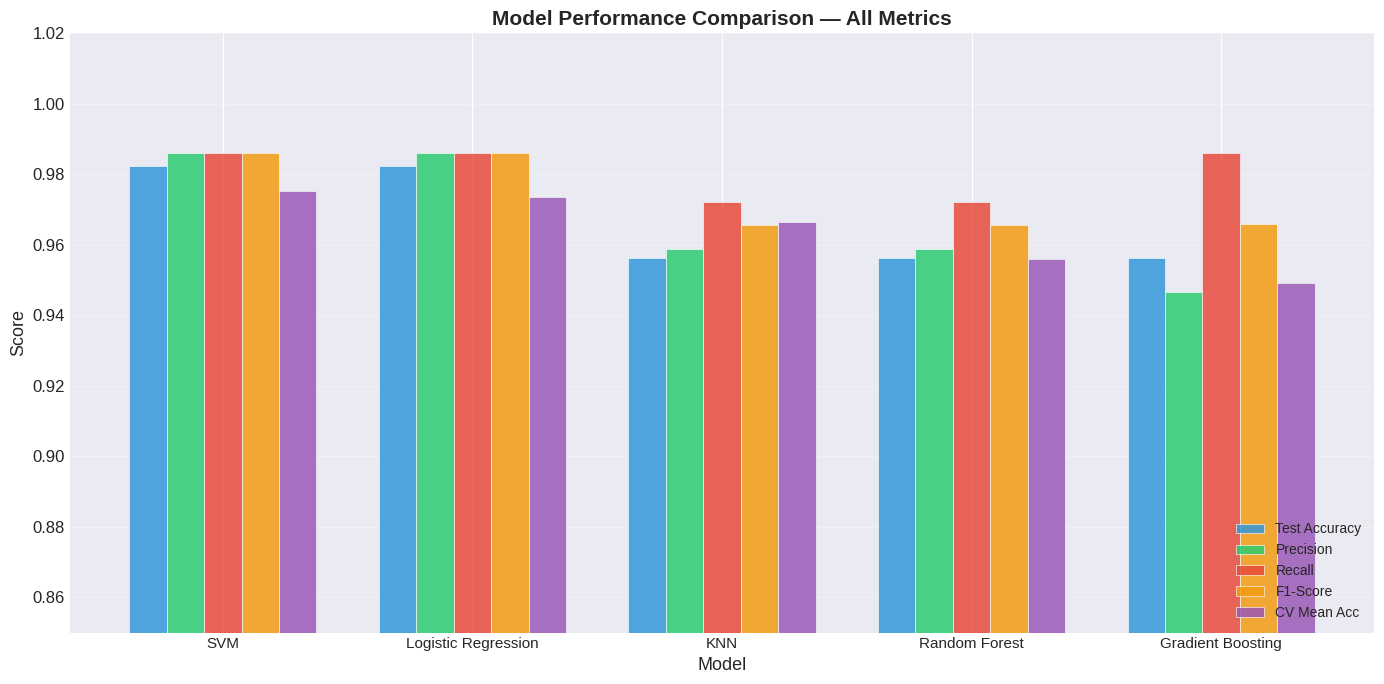


🥇 Best Model: SVM
   Test Accuracy:  0.9825
   F1-Score:       0.9861
   CV Mean Acc:    0.9754 ± 0.0195


In [23]:
# Visual comparison — grouped bar chart
fig, ax = plt.subplots(figsize=(14, 7))

metrics = ['Test Accuracy', 'Precision', 'Recall', 'F1-Score', 'CV Mean Acc']
x = np.arange(len(comparison))
width = 0.15

metric_colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']

for i, (metric, color) in enumerate(zip(metrics, metric_colors)):
    bars = ax.bar(x + i * width, comparison[metric], width, label=metric,
                  color=color, edgecolor='white', linewidth=0.5, alpha=0.85)

ax.set_xlabel('Model', fontsize=13)
ax.set_ylabel('Score', fontsize=13)
ax.set_title('Model Performance Comparison — All Metrics', fontweight='bold', fontsize=15)
ax.set_xticks(x + width * 2)
ax.set_xticklabels(comparison['Model'], fontsize=11)
ax.legend(fontsize=10, loc='lower right', framealpha=0.9)
ax.set_ylim([0.85, 1.02])
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../images/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Print winner
best = comparison.iloc[0]
print(f"\n🥇 Best Model: {best['Model']}")
print(f"   Test Accuracy:  {best['Test Accuracy']:.4f}")
print(f"   F1-Score:       {best['F1-Score']:.4f}")
print(f"   CV Mean Acc:    {best['CV Mean Acc']:.4f} ± {best['CV Std']:.4f}")

## 9. 📝 Conclusion

### Key Findings:
- **5 models** were trained and evaluated on the Breast Cancer Wisconsin dataset
- **Comprehensive evaluation** using accuracy, precision, recall, F1-score, ROC-AUC, and cross-validation
- **Feature scaling** with StandardScaler improved model performance across all classifiers
- **Stratified 5-fold cross-validation** provided robust performance estimates

### Clinical Significance:
- High **recall** is critical in cancer diagnosis — we want to minimize false negatives (missed cancers)
- The best model achieves strong performance across all metrics, making it suitable as a **computer-aided diagnostic tool**

---
*Built as part of the Breast Cancer Prediction Engine portfolio project.*